In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import fsolve

In [2]:
# Parameters

asset = "MSFT"  # Microsoft
ticker = yf.Ticker(asset)                          
S0 = ticker.history(period="1d")["Close"].iloc[-1]  # Spot price in $
sigma0 = 0.6    # volatility
r= 0.03         # interest rate
q = 0           # dividend yield
print(S0)

523.8800048828125


In [3]:
expiries = ticker.options  # available maturity for the options
expiries
expiries = list(expiries)
expiries

['2026-11-16',
 '2026-11-18',
 '2026-11-20',
 '2026-11-23',
 '2026-11-25',
 '2026-11-27',
 '2026-12-04',
 '2026-12-11',
 '2026-12-18',
 '2026-12-24',
 '2026-12-31',
 '2027-01-15',
 '2027-02-19',
 '2027-03-19',
 '2027-04-16',
 '2027-06-17',
 '2027-09-17',
 '2027-12-17',
 '2028-01-21',
 '2028-06-16',
 '2028-12-15',
 '2029-01-19']

In [4]:
# For each maturity date, we add a price, strike for a call option and put option

L_call = []
L_put = []

for maturity in expiries:

    option_chain = ticker.option_chain(date=maturity)

    call = option_chain.calls
    call["Maturity"] = maturity
    L_call.append(call)

    put = option_chain.puts
    put["Maturity"] = maturity
    L_put.append(put)

df_call= pd.concat(L_call)
df_put = pd.concat(L_put)
df_call


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,Maturity
0,MSFT261116C00425000,2026-11-04 14:35:41+00:00,425.0,120.65,98.2,99.60,0.000000,0.000000,NaN,1.0,0.984375,True,REGULAR,USD,2026-11-16
1,MSFT261116C00430000,2026-11-13 20:57:25+00:00,430.0,94.08,93.1,94.60,0.000000,0.000000,1.0,0.0,1.473635,True,REGULAR,USD,2026-11-16
2,MSFT261116C00435000,2026-11-13 20:55:00+00:00,435.0,89.05,88.2,89.60,0.000000,0.000000,1.0,0.0,0.882814,True,REGULAR,USD,2026-11-16
3,MSFT261116C00445000,2026-11-13 14:50:16+00:00,445.0,77.88,77.9,79.60,-22.620003,-22.507465,3.0,0.0,1.257328,True,REGULAR,USD,2026-11-16
4,MSFT261116C00460000,2026-11-13 19:50:53+00:00,460.0,64.16,63.2,64.60,0.160004,0.250006,4.0,0.0,0.632816,True,REGULAR,USD,2026-11-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,MSFT290119C00780000,2026-11-11 20:49:51+00:00,780.0,41.95,41.0,44.50,0.000000,0.000000,2.0,468.0,0.362307,False,REGULAR,USD,2029-01-19
82,MSFT290119C00790000,2026-11-12 15:52:42+00:00,790.0,41.59,39.5,43.00,0.000000,0.000000,1.0,32.0,0.362426,False,REGULAR,USD,2029-01-19
83,MSFT290119C00795000,2026-11-10 16:17:00+00:00,795.0,46.00,38.5,42.50,0.000000,0.000000,3.0,19.0,0.363330,False,REGULAR,USD,2029-01-19
84,MSFT290119C00800000,2026-11-13 19:33:32+00:00,800.0,39.95,38.0,40.80,1.049999,2.699227,6.0,460.0,0.359740,False,REGULAR,USD,2029-01-19


In [5]:
# Building the dataframes and first cleaning

columns = ["strike",'Maturity',"lastPrice","bid","ask","impliedVolatility","volume"]



df_call = df_call[columns]

df_call["mid"] = 0.5 * (df_call["bid"] + df_call["ask"])

df_call["Maturity"] = pd.to_datetime(df_call["Maturity"])

# filter

# Strike between 80% et 120%
strike_filter = (S0*0.8< df_call["strike"]) & (df_call["strike"]<S0*1.2)
df_call = df_call[strike_filter]

# maturity between today and 3 months 
maturity_filter = (df_call["Maturity"]>pd.Timestamp.today()) & (df_call["Maturity"] < pd.Timestamp.today() + pd.Timedelta(days=100))
df_call = df_call[maturity_filter]

# volume > 50
df_call = df_call[df_call["volume"]>50]

#mid price
# mid_filter = (df_call["mid"] >= 0.10)
# df_call = df_call[mid_filter]

df_call

# Put filter

df_put = df_put[columns]
df_put["mid"] = 0.5 * (df_put["bid"] + df_put["ask"])
df_put["Maturity"] = pd.to_datetime(df_put["Maturity"])



strike_filter = (S0*0.8< df_put["strike"]) & (df_put["strike"]<S0*1.2)
df_put = df_put[strike_filter]

maturity_filter = (df_put["Maturity"]>pd.Timestamp.today()) & (df_put["Maturity"] < pd.Timestamp.today() + pd.Timedelta(days=100))
df_put = df_put[maturity_filter]

# volume > 50
df_put = df_put[df_put["volume"]>50]

# mid price
mid_filter = (df_put["mid"] >= 0.10)
df_put = df_put[mid_filter]

df_call


C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\31573668.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_call["mid"] = 0.5 * (df_call["bid"] + df_call["ask"])
C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\31573668.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_call["Maturity"] = pd.to_datetime(df_call["Maturity"])


,strike,Maturity,lastPrice,bid,ask,impliedVolatility,volume,mid
11,490.0,2026-11-16,34.50,33.25,34.75,0.642093,212.0,34.000
19,510.0,2026-11-16,15.75,13.95,15.25,0.385138,68.0,14.600
21,515.0,2026-11-16,10.14,9.75,10.50,0.313728,475.0,10.125
22,517.5,2026-11-16,9.42,7.85,8.40,0.293342,372.0,8.125
23,520.0,2026-11-16,6.43,6.05,6.50,0.277839,1367.0,6.275
...,...,...,...,...,...,...,...,...
62,580.0,2027-02-19,14.15,12.10,14.40,0.314658,82.0,13.250
63,585.0,2027-02-19,12.46,10.90,12.95,0.311393,137.0,11.925
65,595.0,2027-02-19,9.96,8.65,10.60,0.307929,69.0,9.625
66,600.0,2027-02-19,8.79,8.35,9.50,0.305549,64.0,8.925


In [6]:
# Price Call/Put with Black and Scholes
def black_scholes(S0,K,r,sigma,T,q,option_type="call"):

    d1= (np.log(S0/K)+(0.5*sigma**2*+r-q)*T)/(sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    if option_type == "call":
        return S0*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2) 
    
    if option_type == "put":
        return K*np.exp(-r*T)*norm.cdf(-d2)-S0*norm.cdf(-d1) 

In [7]:
option_type = "call"

In [8]:
def Newton(f,df,x0,error1,error2):
    x = x0
    while abs(f(x))>error1 or abs(x-x0)>error2:
        x0 = x
        x = x - f(x)/df(x)
    return x

In [9]:
# Function to get the determine the implied volatility
def implied_volatility(S0,K,T,r,q,market_price):
    def f(sigma):
        return black_scholes(S0,K,r,sigma,T,q,option_type)-market_price
    return fsolve(f,x0=sigma0,xtol=1e-8,maxfev=500)  

In [10]:
# For a given maturity date, we want to know the value of the implied volatility for each strike

smile = {}

for t in df_call["Maturity"].drop_duplicates():
    time_to_maturity = (t - pd.Timestamp.today()).days / 365
    L_implied_vol=[]
    L_K = []

    df_t = df_call[df_call["Maturity"]==t]

    for _,row in df_t.iterrows():
        K = row["strike"]
        market_price = row["lastPrice"]     # or  row["mid"] 

        implied_vol = float(implied_volatility(S0,K,time_to_maturity,r,q,market_price)[0])
        L_implied_vol.append(implied_vol)
        L_K.append(K)
    
    smile[t] = {"K":L_K,
                "iv":L_implied_vol}
        

C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\358303648.py:4: RuntimeWarning: divide by zero encountered in divide
  d1= (np.log(S0/K)+(0.5*sigma**2*+r-q)*T)/(sigma*np.sqrt(T))
C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\1464899031.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(f,x0=sigma0,xtol=1e-8,maxfev=500)


In [11]:
smile

{Timestamp('2026-11-16 00:00:00'): {'K': [490.0,
   510.0,
   515.0,
   517.5,
   520.0,
   522.5,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   552.5,
   560.0],
  'iv': [0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6]},
 Timestamp('2026-11-18 00:00:00'): {'K': [490.0,
   492.5,
   512.5,
   515.0,
   517.5,
   520.0,
   522.5,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   552.5,
   555.0,
   560.0,
   567.5,
   570.0],
  'iv': [0.7846286560236272,
   0.7606268004415747,
   0.5226357340981802,
   0.4656609817422917,
   0.5447959633483548,
   0.43025218476127175,
   0.5339554745116151,
   0.43367718298928354,
   0.43297864629153837,
   0.41274176477464697,
   0.42382183260727413,
   0.40213196817954916,
   0.4062517410538302,
   0.41399751554176684,
   0.

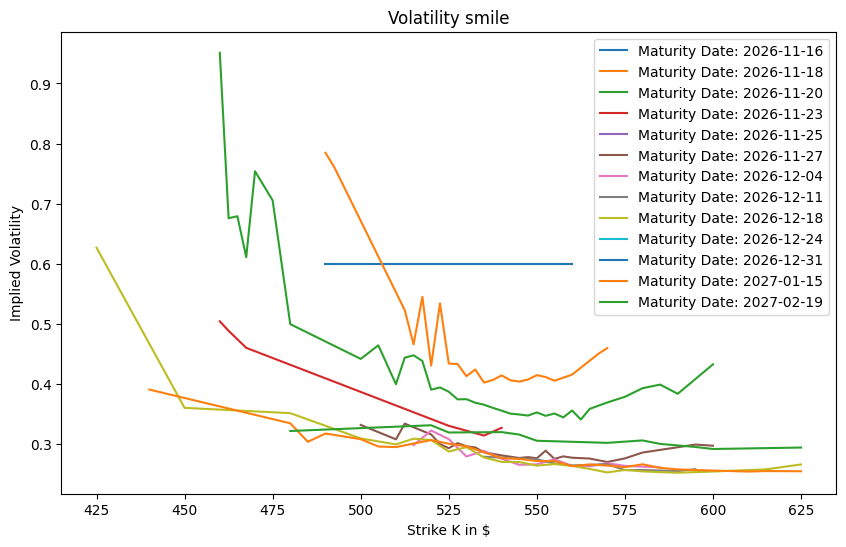

In [12]:
plt.figure(figsize=(10,6))
for t, data in smile.items():  # smile.items() renvoie couples (clé,valeur)
    plt.plot(data["K"],data["iv"],label="Maturity Date: " + str(t.date()))

plt.xlabel("Strike K in $")
plt.ylabel("Implied Volatility")
plt.title('Volatility smile')
plt.legend()
plt.show()

In [13]:
# For a given strike, we want to know the value of the implied volatility for each maturity

term_structure = {}
df_call = df_call.sort_values(by="strike",ascending=True)
for K in df_call["strike"].drop_duplicates():
    L_implied_vol=[]
    L_T = []

    df_K = df_call[df_call["strike"]==K]

    for _,row in df_K.iterrows():
        T = row["Maturity"]
        time_to_maturity = (T - pd.Timestamp.today()).days / 365
        market_price = row["lastPrice"]  # or row["mid"]

        implied_vol = float(implied_volatility(S0,K,time_to_maturity,r,q,market_price)[0])  # [0]
        
        L_implied_vol.append(implied_vol)
        #implied_vol = row["impliedVolatility"]
        L_T.append(T)
    
    term_structure[K] = {"T":L_T,
                "iv":L_implied_vol}
print(term_structure)

C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\358303648.py:4: RuntimeWarning: divide by zero encountered in divide
  d1= (np.log(S0/K)+(0.5*sigma**2*+r-q)*T)/(sigma*np.sqrt(T))
C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\1464899031.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(f,x0=sigma0,xtol=1e-8,maxfev=500)
C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\358303648.py:4: RuntimeWarning: divide by zero encountered in divide
  d1= (np.log(S0/K)+(0.5*sigma**2*+r-q)*T)/(sigma*np.sqrt(T))
C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\1464899031.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  return fsolve(f,x0=sigma0,xtol=1e-8,maxfev=500)
C:\Users\antoi\AppData\Local\Temp\ipykernel_24520\358303648.py:4: RuntimeWarning: divide by zero encountered in divide
  d1= (np.log(S0/K)+(0.5*sigma**2*+r-q)*T

{425.0: {'T': [Timestamp('2026-12-18 00:00:00')], 'iv': [0.6267154092056171]}, 440.0: {'T': [Timestamp('2027-01-15 00:00:00')], 'iv': [0.3903809794112614]}, 450.0: {'T': [Timestamp('2026-12-18 00:00:00')], 'iv': [0.35996193813410354]}, 460.0: {'T': [Timestamp('2026-11-20 00:00:00'), Timestamp('2026-11-23 00:00:00')], 'iv': [0.9512217661120808, 0.5040041260824111]}, 462.5: {'T': [Timestamp('2026-11-23 00:00:00'), Timestamp('2026-11-20 00:00:00')], 'iv': [0.4881536335753021, 0.6756792712731577]}, 465.0: {'T': [Timestamp('2026-11-20 00:00:00'), Timestamp('2026-11-23 00:00:00')], 'iv': [0.678983430489285, 0.474162791132035]}, 467.5: {'T': [Timestamp('2026-11-23 00:00:00'), Timestamp('2026-11-20 00:00:00')], 'iv': [0.4598888293694828, 0.6108701882685602]}, 470.0: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.7538457389139155]}, 475.0: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.7053890013454075]}, 480.0: {'T': [Timestamp('2026-12-18 00:00:00'), Timestamp('2026-11-20 00:00:00'), 

In [14]:
term_structure

{425.0: {'T': [Timestamp('2026-12-18 00:00:00')], 'iv': [0.6267154092056171]},
 440.0: {'T': [Timestamp('2027-01-15 00:00:00')], 'iv': [0.3903809794112614]},
 450.0: {'T': [Timestamp('2026-12-18 00:00:00')], 'iv': [0.35996193813410354]},
 460.0: {'T': [Timestamp('2026-11-20 00:00:00'),
   Timestamp('2026-11-23 00:00:00')],
  'iv': [0.9512217661120808, 0.5040041260824111]},
 462.5: {'T': [Timestamp('2026-11-23 00:00:00'),
   Timestamp('2026-11-20 00:00:00')],
  'iv': [0.4881536335753021, 0.6756792712731577]},
 465.0: {'T': [Timestamp('2026-11-20 00:00:00'),
   Timestamp('2026-11-23 00:00:00')],
  'iv': [0.678983430489285, 0.474162791132035]},
 467.5: {'T': [Timestamp('2026-11-23 00:00:00'),
   Timestamp('2026-11-20 00:00:00')],
  'iv': [0.4598888293694828, 0.6108701882685602]},
 470.0: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.7538457389139155]},
 475.0: {'T': [Timestamp('2026-11-20 00:00:00')], 'iv': [0.7053890013454075]},
 480.0: {'T': [Timestamp('2026-12-18 00:00:00'),
   Ti

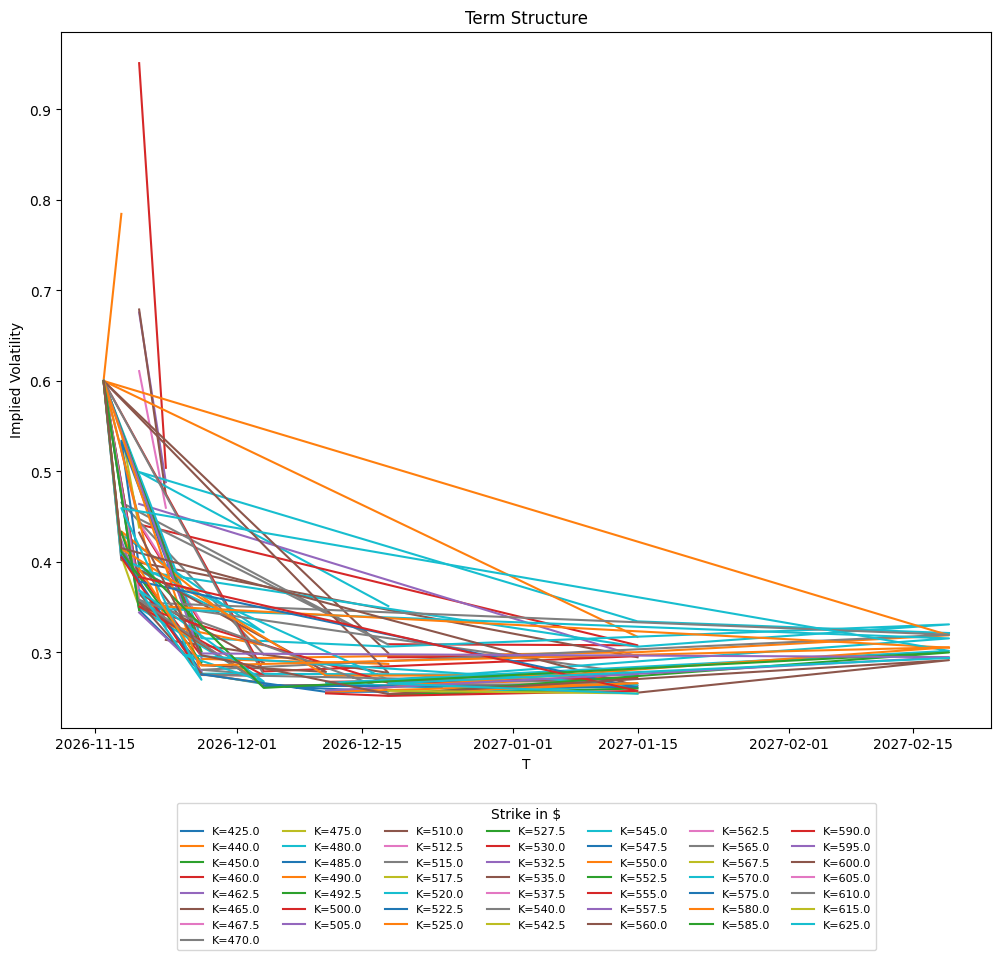

In [15]:
plt.figure(figsize=(12,12))
Ks_to_plot = np.arange(360,450,10) #[360.0, 370 ,380.0,390,400,410]
for K, data in term_structure.items():  # term_structure.items() renvoie couples (clé,valeur)
    plt.plot(data["T"],data["iv"],label=f"K={K}")

plt.xlabel("T")
plt.ylabel("Implied Volatility")
plt.title('Term Structure')

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=7,           
    title="Strike in $",
    fontsize=8,
    frameon=True
)

plt.subplots_adjust(bottom=0.30)

plt.show()

In [16]:
smile

{Timestamp('2026-11-16 00:00:00'): {'K': [490.0,
   510.0,
   515.0,
   517.5,
   520.0,
   522.5,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   552.5,
   560.0],
  'iv': [0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6,
   0.6]},
 Timestamp('2026-11-18 00:00:00'): {'K': [490.0,
   492.5,
   512.5,
   515.0,
   517.5,
   520.0,
   522.5,
   525.0,
   527.5,
   530.0,
   532.5,
   535.0,
   537.5,
   540.0,
   542.5,
   545.0,
   547.5,
   550.0,
   552.5,
   555.0,
   560.0,
   567.5,
   570.0],
  'iv': [0.7846286560236272,
   0.7606268004415747,
   0.5226357340981802,
   0.4656609817422917,
   0.5447959633483548,
   0.43025218476127175,
   0.5339554745116151,
   0.43367718298928354,
   0.43297864629153837,
   0.41274176477464697,
   0.42382183260727413,
   0.40213196817954916,
   0.4062517410538302,
   0.41399751554176684,
   0.

In [17]:
rows = []

for date in smile:
    #print(smile[date]["K"])
    print(smile[date]["iv"])
    list_strike = smile[date]["K"]
    list_iv = smile[date]["iv"]
    for i in range(len(list_strike)):
        r = {"T":date,"K":list_strike[i],"IV":list_iv[i]}
        rows.append(r)

df_smile = pd.DataFrame(rows)



    
        
    
  


[0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6]
[0.7846286560236272, 0.7606268004415747, 0.5226357340981802, 0.4656609817422917, 0.5447959633483548, 0.43025218476127175, 0.5339554745116151, 0.43367718298928354, 0.43297864629153837, 0.41274176477464697, 0.42382183260727413, 0.40213196817954916, 0.4062517410538302, 0.41399751554176684, 0.4058791886837579, 0.4036508197016244, 0.4071595023113631, 0.41441616239619017, 0.4112680275955683, 0.40512583991493234, 0.41524337426654473, 0.4501060809931439, 0.4594150597589522]
[0.9512217661120808, 0.6756792712731577, 0.678983430489285, 0.6108701882685602, 0.7538457389139155, 0.7053890013454075, 0.4993761692837957, 0.4414470075562354, 0.464071286573337, 0.3993242891551556, 0.4434555247080185, 0.4475223940135396, 0.4380247390738253, 0.3902547190276836, 0.3939231655230158, 0.386740756687229, 0.374109512139367, 0.37436801524505314, 0.368501302877443, 0.36515031081495847, 0.35996552391570824, 0.355270449642

In [18]:
df_smile

,T,K,IV
0,2026-11-16,490.0,0.600000
1,2026-11-16,510.0,0.600000
2,2026-11-16,515.0,0.600000
3,2026-11-16,517.5,0.600000
4,2026-11-16,520.0,0.600000
...,...,...,...
194,2027-02-19,580.0,0.305694
195,2027-02-19,585.0,0.299944
196,2027-02-19,595.0,0.294813
197,2027-02-19,600.0,0.291438


In [19]:
# Computing time to maturity
df_smile["T"].dtype

valuation_date = pd.Timestamp.today().normalize() # today
print(valuation_date)

df_smile["Time to maturity in years"] = (df_smile["T"]-valuation_date).dt.total_seconds()/(365*24*3600)
df_smile


2026-11-15 00:00:00


,T,K,IV,Time to maturity in years
0,2026-11-16,490.0,0.600000,0.002740
1,2026-11-16,510.0,0.600000,0.002740
2,2026-11-16,515.0,0.600000,0.002740
3,2026-11-16,517.5,0.600000,0.002740
4,2026-11-16,520.0,0.600000,0.002740
...,...,...,...,...
194,2027-02-19,580.0,0.305694,0.263014
195,2027-02-19,585.0,0.299944,0.263014
196,2027-02-19,595.0,0.294813,0.263014
197,2027-02-19,600.0,0.291438,0.263014


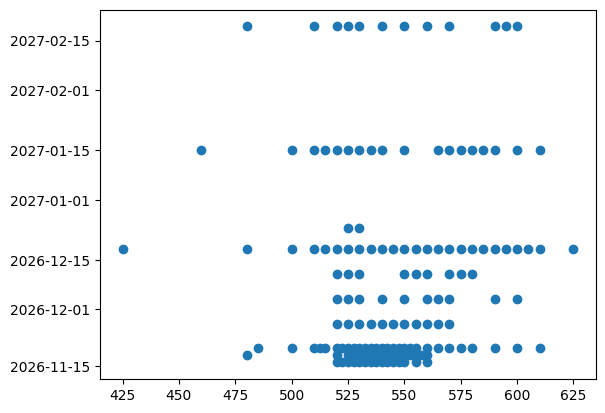

In [23]:
plt.plot(df_smile["K"],df_smile["T"],"o")

Text(0, 0.5, 'T')

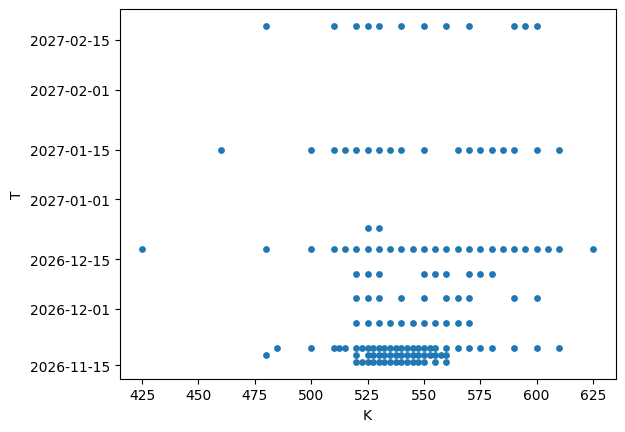

In [25]:
plt.scatter(df_smile["K"],df_smile["T"],s=15)
plt.xlabel("K")
plt.ylabel("T")

In [20]:
data_points = df_smile[["K","Time to maturity in years"]]
data_points

,K,Time to maturity in years
0,490.0,0.002740
1,510.0,0.002740
2,515.0,0.002740
3,517.5,0.002740
4,520.0,0.002740
...,...,...
194,580.0,0.263014
195,585.0,0.263014
196,595.0,0.263014
197,600.0,0.263014


In [21]:
data_points = data_points.to_numpy()  # every row contains couple (K,T)
data_points

array([[4.90000000e+02, 2.73972603e-03],
       [5.10000000e+02, 2.73972603e-03],
       [5.15000000e+02, 2.73972603e-03],
       [5.17500000e+02, 2.73972603e-03],
       [5.20000000e+02, 2.73972603e-03],
       [5.22500000e+02, 2.73972603e-03],
       [5.25000000e+02, 2.73972603e-03],
       [5.27500000e+02, 2.73972603e-03],
       [5.30000000e+02, 2.73972603e-03],
       [5.32500000e+02, 2.73972603e-03],
       [5.35000000e+02, 2.73972603e-03],
       [5.37500000e+02, 2.73972603e-03],
       [5.40000000e+02, 2.73972603e-03],
       [5.42500000e+02, 2.73972603e-03],
       [5.45000000e+02, 2.73972603e-03],
       [5.47500000e+02, 2.73972603e-03],
       [5.50000000e+02, 2.73972603e-03],
       [5.52500000e+02, 2.73972603e-03],
       [5.60000000e+02, 2.73972603e-03],
       [4.90000000e+02, 8.21917808e-03],
       [4.92500000e+02, 8.21917808e-03],
       [5.12500000e+02, 8.21917808e-03],
       [5.15000000e+02, 8.21917808e-03],
       [5.17500000e+02, 8.21917808e-03],
       [5.200000

In [22]:
from scipy.spatial import Delaunay

triangle = Delaunay(data_points)  # on calcule les triangles
print(triangle)

In [23]:
triangle.simplices  # donne sommet triangle: ex [117,135,90]  117 correspond à indice de ligne de data_points

array([[161, 136, 187],
       [136, 161, 135],
       [157,  79, 158],
       ...,
       [ 31,  63,  62],
       [ 63,  33,  64],
       [ 63,  32,  33]], shape=(359, 3), dtype=int32)

In [24]:
data_points[:,0] # on récupère les strike
data_points[:,1] # on récupère les T

array([0.00273973, 0.00273973, 0.00273973, 0.00273973, 0.00273973,
       0.00273973, 0.00273973, 0.00273973, 0.00273973, 0.00273973,
       0.00273973, 0.00273973, 0.00273973, 0.00273973, 0.00273973,
       0.00273973, 0.00273973, 0.00273973, 0.00273973, 0.00821918,
       0.00821918, 0.00821918, 0.00821918, 0.00821918, 0.00821918,
       0.00821918, 0.00821918, 0.00821918, 0.00821918, 0.00821918,
       0.00821918, 0.00821918, 0.00821918, 0.00821918, 0.00821918,
       0.00821918, 0.00821918, 0.00821918, 0.00821918, 0.00821918,
       0.00821918, 0.00821918, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369863,
       0.01369863, 0.01369863, 0.01369863, 0.01369863, 0.01369

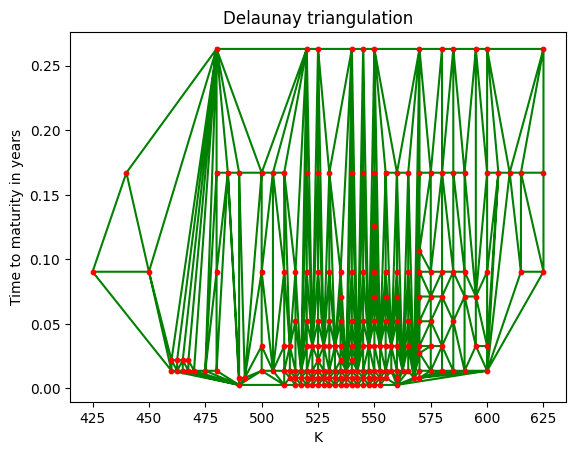

In [25]:
# Maillage

# Triangles
plt.triplot(
    data_points[:,0],
    data_points[:,1],
    triangle.simplices,
    color="green"
)

# Data points
plt.scatter(data_points[:,0],data_points[:,1],s=10,color='red')

plt.xlabel("K")
plt.ylabel("Time to maturity in years")
plt.title("Delaunay triangulation")
plt.show()

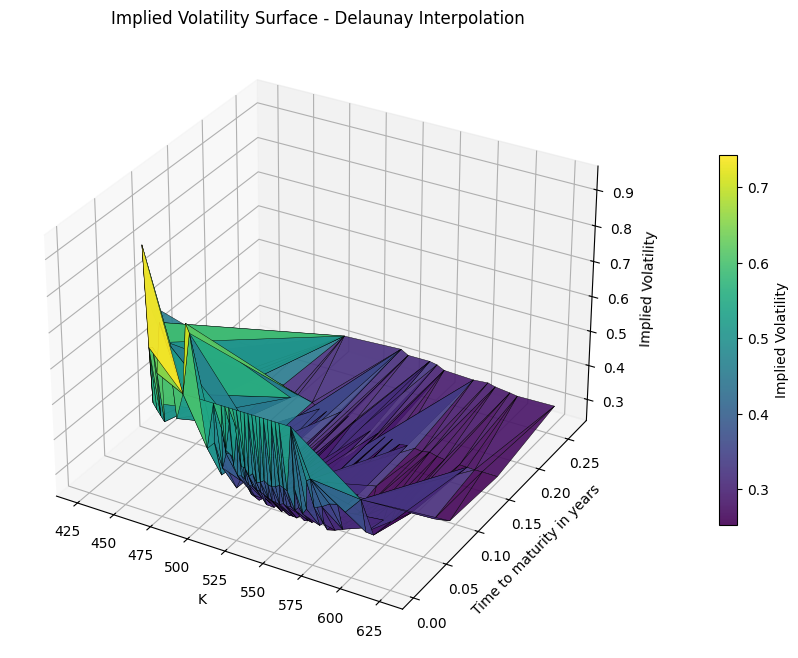

In [26]:
# Building the surface


# Sommmets 
K = data_points[:,0]
T = data_points[:,1]
IV = df_smile["IV"].to_numpy()

# Création d'un graphique en 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

# On ajoute les triangles calculés précédemment
surface = ax.plot_trisurf(
    K,
    T,
    IV,
    triangles = triangle.simplices,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.9

)

ax.set_xlabel("K")
ax.set_ylabel("Time to maturity in years")
ax.set_zlabel("Implied Volatility")
ax.set_title("Implied Volatility Surface - Delaunay Interpolation")

fig.colorbar(
     surface,
    ax=ax,
    shrink=0.6,
    pad=0.1,
    label="Implied Volatility"
)

plt.show()


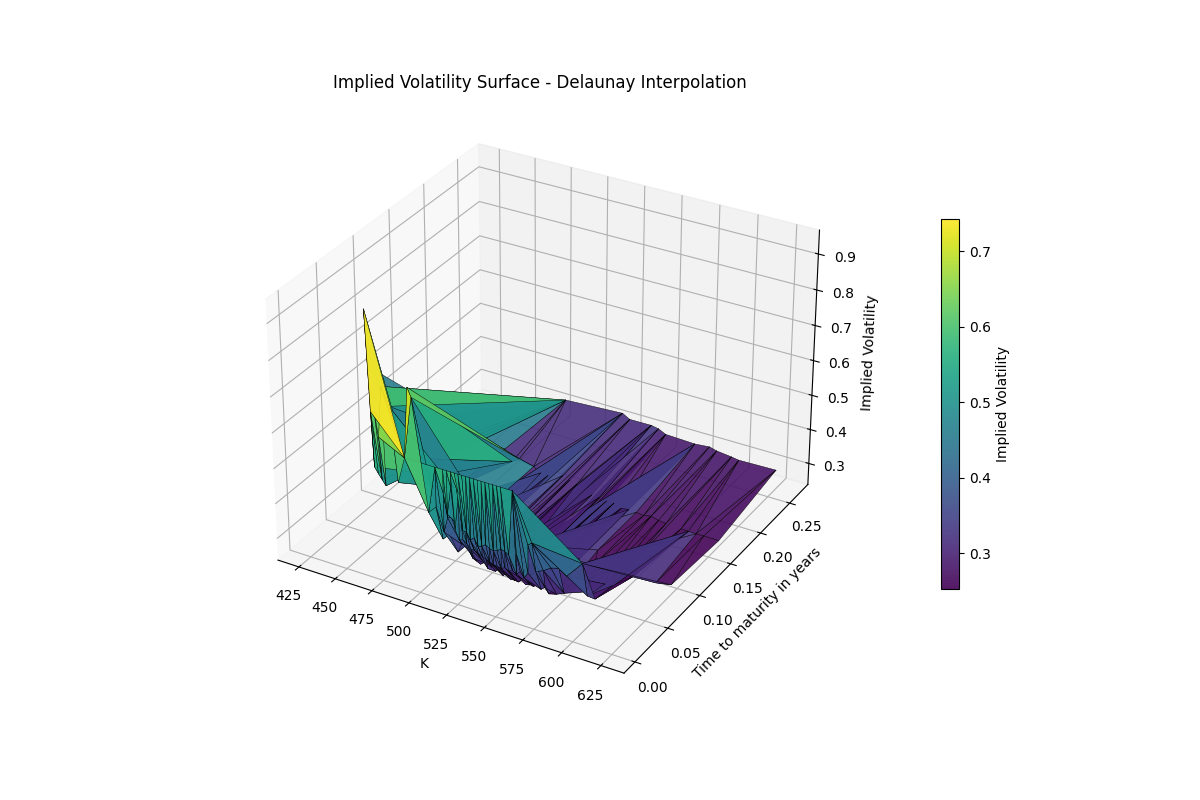

In [27]:
# Building the surface
# pour avoir surface interactive

%matplotlib widget  
# Sommmets 
K = data_points[:,0]
T = data_points[:,1]
IV = df_smile["IV"].to_numpy()

# Création d'un graphique en 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

# On ajoute les triangles calculés précédemment
surface = ax.plot_trisurf(
    K,
    T,
    IV,
    triangles = triangle.simplices,
    cmap="viridis",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.9

)

ax.set_xlabel("K")
ax.set_ylabel("Time to maturity in years")
ax.set_zlabel("Implied Volatility")
ax.set_title("Implied Volatility Surface - Delaunay Interpolation")

fig.colorbar(
     surface,
    ax=ax,
    shrink=0.6,
    pad=0.1,
    label="Implied Volatility"
)

plt.show()


Errors

In [28]:
df_smile

,T,K,IV,Time to maturity in years
0,2026-11-16,490.0,0.600000,0.002740
1,2026-11-16,510.0,0.600000,0.002740
2,2026-11-16,515.0,0.600000,0.002740
3,2026-11-16,517.5,0.600000,0.002740
4,2026-11-16,520.0,0.600000,0.002740
...,...,...,...,...
194,2027-02-19,580.0,0.305694,0.263014
195,2027-02-19,585.0,0.299944,0.263014
196,2027-02-19,595.0,0.294813,0.263014
197,2027-02-19,600.0,0.291438,0.263014


In [29]:
data_points

array([[4.90000000e+02, 2.73972603e-03],
       [5.10000000e+02, 2.73972603e-03],
       [5.15000000e+02, 2.73972603e-03],
       [5.17500000e+02, 2.73972603e-03],
       [5.20000000e+02, 2.73972603e-03],
       [5.22500000e+02, 2.73972603e-03],
       [5.25000000e+02, 2.73972603e-03],
       [5.27500000e+02, 2.73972603e-03],
       [5.30000000e+02, 2.73972603e-03],
       [5.32500000e+02, 2.73972603e-03],
       [5.35000000e+02, 2.73972603e-03],
       [5.37500000e+02, 2.73972603e-03],
       [5.40000000e+02, 2.73972603e-03],
       [5.42500000e+02, 2.73972603e-03],
       [5.45000000e+02, 2.73972603e-03],
       [5.47500000e+02, 2.73972603e-03],
       [5.50000000e+02, 2.73972603e-03],
       [5.52500000e+02, 2.73972603e-03],
       [5.60000000e+02, 2.73972603e-03],
       [4.90000000e+02, 8.21917808e-03],
       [4.92500000e+02, 8.21917808e-03],
       [5.12500000e+02, 8.21917808e-03],
       [5.15000000e+02, 8.21917808e-03],
       [5.17500000e+02, 8.21917808e-03],
       [5.200000

In [30]:
IV

array([0.6       , 0.6       , 0.6       , 0.6       , 0.6       ,
       0.6       , 0.6       , 0.6       , 0.6       , 0.6       ,
       0.6       , 0.6       , 0.6       , 0.6       , 0.6       ,
       0.6       , 0.6       , 0.6       , 0.6       , 0.78462866,
       0.7606268 , 0.52263573, 0.46566098, 0.54479596, 0.43025218,
       0.53395547, 0.43367718, 0.43297865, 0.41274176, 0.42382183,
       0.40213197, 0.40625174, 0.41399752, 0.40587919, 0.40365082,
       0.4071595 , 0.41441616, 0.41126803, 0.40512584, 0.41524337,
       0.45010608, 0.45941506, 0.95122177, 0.67567927, 0.67898343,
       0.61087019, 0.75384574, 0.705389  , 0.49937617, 0.44144701,
       0.46407129, 0.39932429, 0.44345552, 0.44752239, 0.43802474,
       0.39025472, 0.39392317, 0.38674076, 0.37410951, 0.37436802,
       0.3685013 , 0.36515031, 0.35996552, 0.35527045, 0.3503202 ,
       0.34889443, 0.34711296, 0.35227882, 0.3466547 , 0.35054921,
       0.3440364 , 0.35553543, 0.34048742, 0.35824611, 0.36890

In [32]:
triangle = Delaunay(data_points)  # on calcule les triangles
triangle

In [ ]:
from scipy.interpolate import LinearNDInterpolator

# Volatility for position (K,T)
surface_iv = LinearNDInterpolator(triangle,IV)

surface_iv

In [36]:
# Pour chaque couple (K,T) du dataframe, on calcule la vol donnée par la surface
df_smile["IV_fit"] = surface_iv(data_points)
df_smile

,T,K,IV,Time to maturity in years,IV_fit
0,2026-11-16,490.0,0.600000,0.002740,0.600000
1,2026-11-16,510.0,0.600000,0.002740,0.600000
2,2026-11-16,515.0,0.600000,0.002740,0.600000
3,2026-11-16,517.5,0.600000,0.002740,0.600000
4,2026-11-16,520.0,0.600000,0.002740,0.600000
...,...,...,...,...,...
194,2027-02-19,580.0,0.305694,0.263014,0.305694
195,2027-02-19,585.0,0.299944,0.263014,0.299944
196,2027-02-19,595.0,0.294813,0.263014,0.294813
197,2027-02-19,600.0,0.291438,0.263014,0.291438


In [37]:
# Residuals

df_smile["residual"] = df_smile["IV_fit"] - df_smile["IV"]
df_smile

,T,K,IV,Time to maturity in years,IV_fit,residual
0,2026-11-16,490.0,0.600000,0.002740,0.600000,0.0
1,2026-11-16,510.0,0.600000,0.002740,0.600000,0.0
2,2026-11-16,515.0,0.600000,0.002740,0.600000,0.0
3,2026-11-16,517.5,0.600000,0.002740,0.600000,0.0
4,2026-11-16,520.0,0.600000,0.002740,0.600000,0.0
...,...,...,...,...,...,...
194,2027-02-19,580.0,0.305694,0.263014,0.305694,0.0
195,2027-02-19,585.0,0.299944,0.263014,0.299944,0.0
196,2027-02-19,595.0,0.294813,0.263014,0.294813,0.0
197,2027-02-19,600.0,0.291438,0.263014,0.291438,0.0


In [42]:
error = df_smile["residual"].to_numpy()
error

array([ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  

In [ ]:
MAE = np.mean(abs(error))
RMSE = np.mean(np.sqrt(error**2))

print(f"MAE = {MAE}")
print(f"RMSE = {RMSE}")

# La surface reproduit correctement les volatilités qui ont servi à la construire. 

MAE = 2.2316040695983046e-18
RMSE = 2.2316040695983046e-18
